# BEED study — analysis walkthrough

This notebook walks through the main pipeline: data audit, provenance check, leakage diagnostics, a random-versus-blocked comparison, and the stored results produced by `run_all.py`. All numbers are computed live from the code in `src/beed` or loaded from `results/`.

In [1]:
import sys, json
sys.path.insert(0, 'src')
import numpy as np, pandas as pd
from beed import config as C, data, features, evaluation as E, experiments as X
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

## 1. Load data and basic checks

In [2]:
df, Xr, y, pos = data.load_beed()
print(df.shape); print(df.y.value_counts().sort_index())
print('duplicate rows:', df.duplicated().sum())
print('label changes at rows:', np.where(np.diff(y)!=0)[0])

(8000, 17)
y
0    2000
1    2000
2    2000
3    2000
Name: count, dtype: int64
duplicate rows: 0
label changes at rows: [1999 3999 5999]


## 2. What do X1–X16 represent? Within-row versus across-row autocorrelation

In [3]:
for c in range(4):
    Xc = Xr[y==c]; Cc = np.corrcoef(Xc.T)
    within = np.mean(np.diag(Cc,1)); across = np.mean([np.corrcoef(Xc[:-1,j], Xc[1:,j])[0,1] for j in range(16)])
    print(f'class {c}: within-row lag-1 r = {within:.3f}; across-row lag-1 r = {across:.3f}; SD = {Xc.std():.1f}')

class 0: within-row lag-1 r = 0.930; across-row lag-1 r = -0.001; SD = 70.0
class 1: within-row lag-1 r = 0.105; across-row lag-1 r = 0.955; SD = 15.1
class 2: within-row lag-1 r = 0.138; across-row lag-1 r = 0.845; SD = 7.9
class 3: within-row lag-1 r = 0.200; across-row lag-1 r = 0.983; SD = 10.2


Class 0 behaves like 16 consecutive samples of one signal (strong within-row, no across-row correlation); classes 1–3 behave like 16 channels sampled at consecutive time points (strong across-row correlation).

## 3. Provenance: exact matching of rows against the Bonn-derived UCI file

In [4]:
data.ensure_bonn()
bm, _ = data.match_to_bonn(Xr, y)
print(bm.groupby('beed_class').agg(n=('index','size'), labels=('bonn_label', lambda s: s.value_counts().to_dict()), offsets=('offset', lambda s: s.value_counts().to_dict()), segments=('bonn_segment','nunique')))

               n     labels      offsets  segments
beed_class                                        
0           2000  {4: 2000}  {158: 2000}       100


## 4. Leakage diagnostic: nearest training neighbour under a random split

In [5]:
pd.read_csv('results/leakage_nearest_neighbour.csv')

,class,nn_same_class,nn_within_1_row,nn_within_5_rows,median_row_distance
0,0,0.9875,0.0000,0.0075,643.0
1,1,0.9825,0.9225,0.9750,1.0
2,2,0.9750,0.8775,0.9325,1.0
3,3,1.0000,0.9525,0.9950,1.0


## 5. Random versus blocked hold-out with a fixed LightGBM (quick re-run)

In [6]:
from lightgbm import LGBMClassifier
groups = data.make_groups(y, pos, bm)
F = features.build_feature_sets(Xr)['raw+eng'].values
for prot in ['random', 'blocked']:
    tr, te = data.holdout(prot, y, pos, groups)
    m = LGBMClassifier(n_estimators=300, num_leaves=31, learning_rate=0.1, subsample=0.8, subsample_freq=1,
                       colsample_bytree=0.8, random_state=C.SEED, verbose=-1, n_jobs=4).fit(F[tr], y[tr])
    print(prot, {k: round(v, 4) for k, v in E.metrics(y[te], m.predict(F[te])).items()})

random {'accuracy': 0.975, 'balanced_acc': 0.975, 'macro_f1': 0.9751, 'kappa': 0.9667}


blocked {'accuracy': 0.8061, 'balanced_acc': 0.8062, 'macro_f1': 0.7975, 'kappa': 0.7415}


## 6. Stored results from `run_all.py`

In [7]:
h = pd.read_csv('results/holdout_metrics.csv')
h[h.task=='4class'].pivot_table(index=['model','features'], columns='protocol', values='macro_f1').round(3)

protocol              blocked  random
model       features                 
1D-CNN      raw         0.722   0.956
BiLSTM      raw         0.468   0.697
LR          eng         0.705   0.749
            raw         0.436   0.483
            raw+eng     0.724   0.760
LightGBM    eng         0.690   0.916
            raw         0.810   0.986
            raw+eng     0.799   0.973
MLP         raw         0.772   0.933
Majority    eng         0.100   0.100
            raw         0.100   0.100
            raw+eng     0.100   0.100
RF          eng         0.664   0.871
            raw         0.795   0.964
            raw+eng     0.755   0.943
SVM-RBF     eng         0.697   0.890
            raw         0.842   0.903
            raw+eng     0.719   0.928
Transformer raw         0.746   0.921
XGBoost     eng         0.686   0.909
            raw         0.798   0.976
            raw+eng     0.784   0.962
kNN         eng         0.631   0.903
            raw         0.710   0.986
            raw+eng     0.633   0.926

In [8]:
pd.read_csv('results/cv_summary.csv').round(3)

,task,protocol,model,macro_f1_mean,macro_f1_sd,accuracy_mean,accuracy_sd,kappa_mean,auc_mean,ece_mean
0,3class,blocked,1D-CNN,0.646,0.098,0.661,0.091,0.493,0.838,0.141
1,3class,blocked,LR,0.544,0.063,0.548,0.065,0.321,0.739,0.167
2,3class,blocked,LightGBM,0.696,0.075,0.704,0.080,0.556,0.865,0.205
3,3class,blocked,MLP,0.661,0.096,0.665,0.099,0.498,0.834,0.110
4,3class,blocked,RF,0.624,0.081,0.639,0.086,0.458,0.821,0.070
5,3class,blocked,SVM-RBF,0.602,0.088,0.616,0.089,0.423,0.797,0.234
6,3class,blocked,XGBoost,0.692,0.083,0.699,0.088,0.548,0.862,0.111
7,3class,blocked,kNN,0.546,0.069,0.554,0.070,0.330,0.712,0.270
8,3class,random,1D-CNN,0.930,0.012,0.930,0.012,0.895,0.988,0.028
9,3class,random,LR,0.694,0.011,0.696,0.011,0.544,0.868,0.034


In [9]:
pd.read_csv('results/stats_friedman.csv').round(4).T

,0,1,2,3
task,3class,3class,4class,4class
protocol,blocked,random,blocked,random
friedman_chi2,55.5,60.4,57.2333,64.7333
friedman_p,0.0,0.0,0.0,0.0
critical_difference,3.3203,3.3203,3.3203,3.3203
n_folds,10,10,10,10
n_models,8,8,8,8
rank_LightGBM,1.8,1.0,2.0,1.1
rank_XGBoost,1.8,2.6,2.1,1.9
rank_MLP,3.2,4.8,3.0,4.9


In [10]:
pd.read_csv('results/edge_deployment.csv').round(3)

,model,input,n_params,size_kB_fp32,latency_ms,macro_f1_blocked_test
0,MLP,raw 16 values,11076,43.266,0.077,0.770
1,1D-CNN,raw 16 values,19524,76.266,0.145,0.714
2,BiLSTM,raw 16 values,20356,79.516,0.220,0.467
3,Transformer,raw 16 values,17796,69.516,0.249,0.745
4,LightGBM,raw+engineered (77),62720,735.000,4.350,0.794


## 7. Key figures

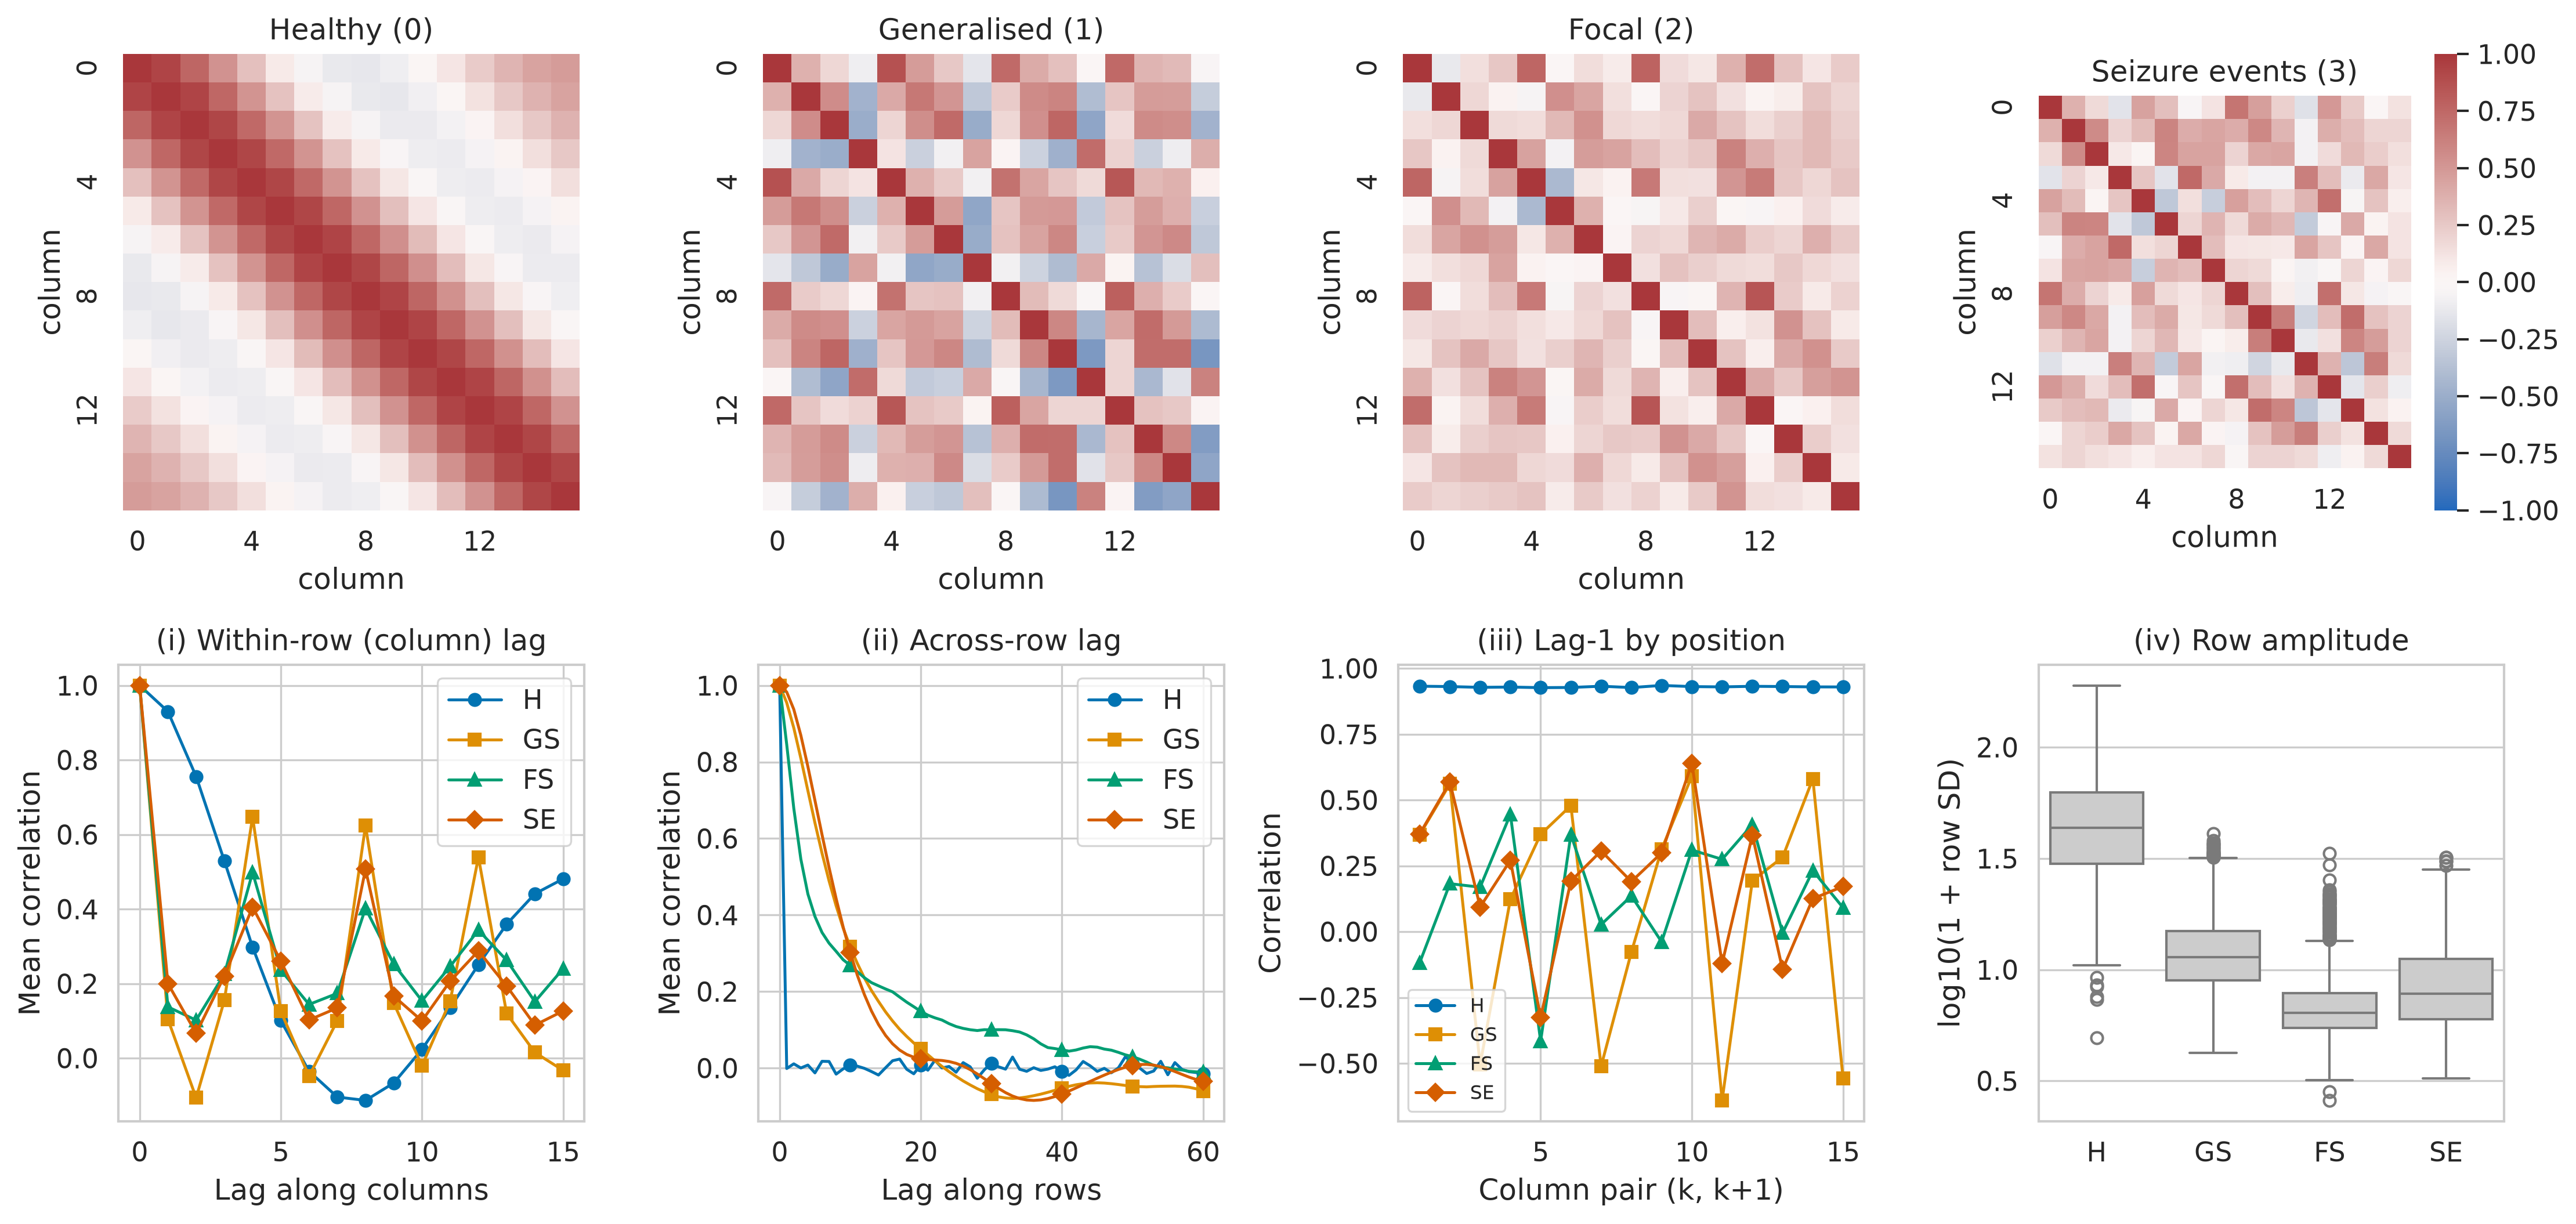

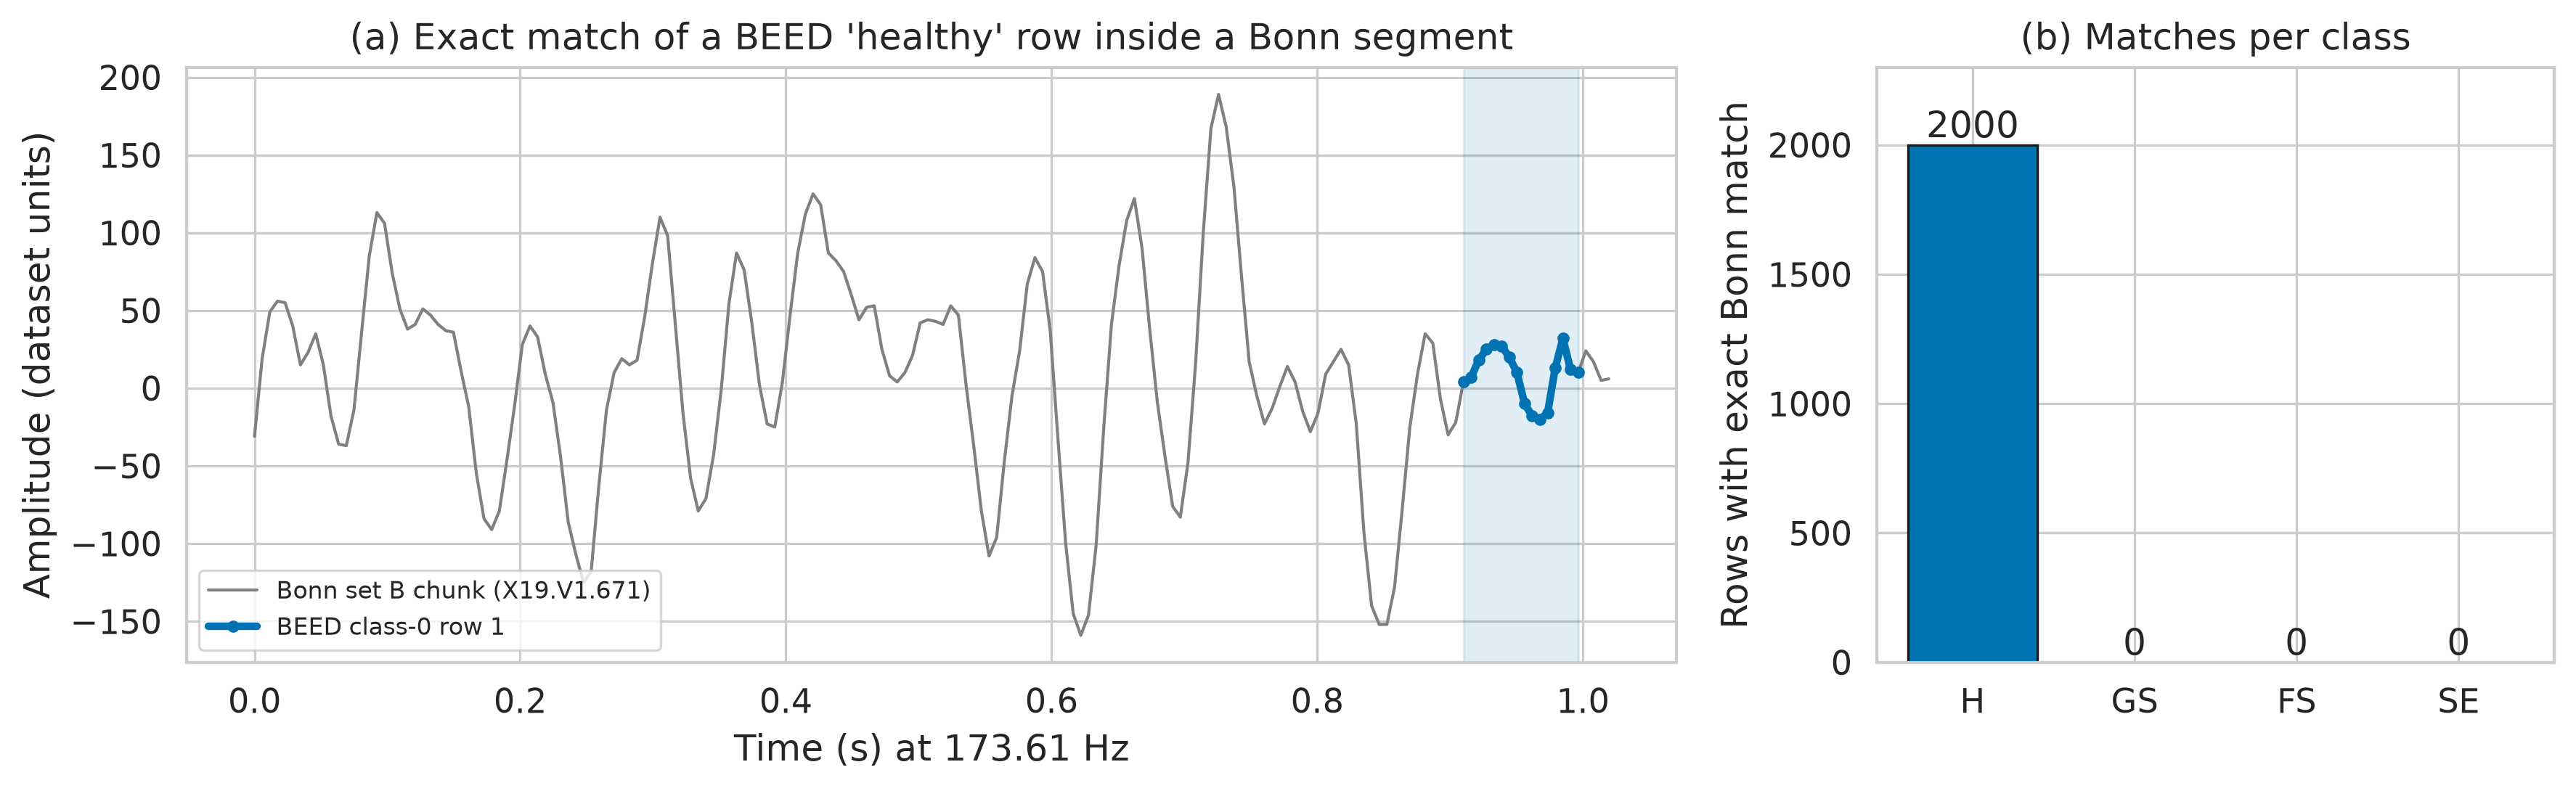

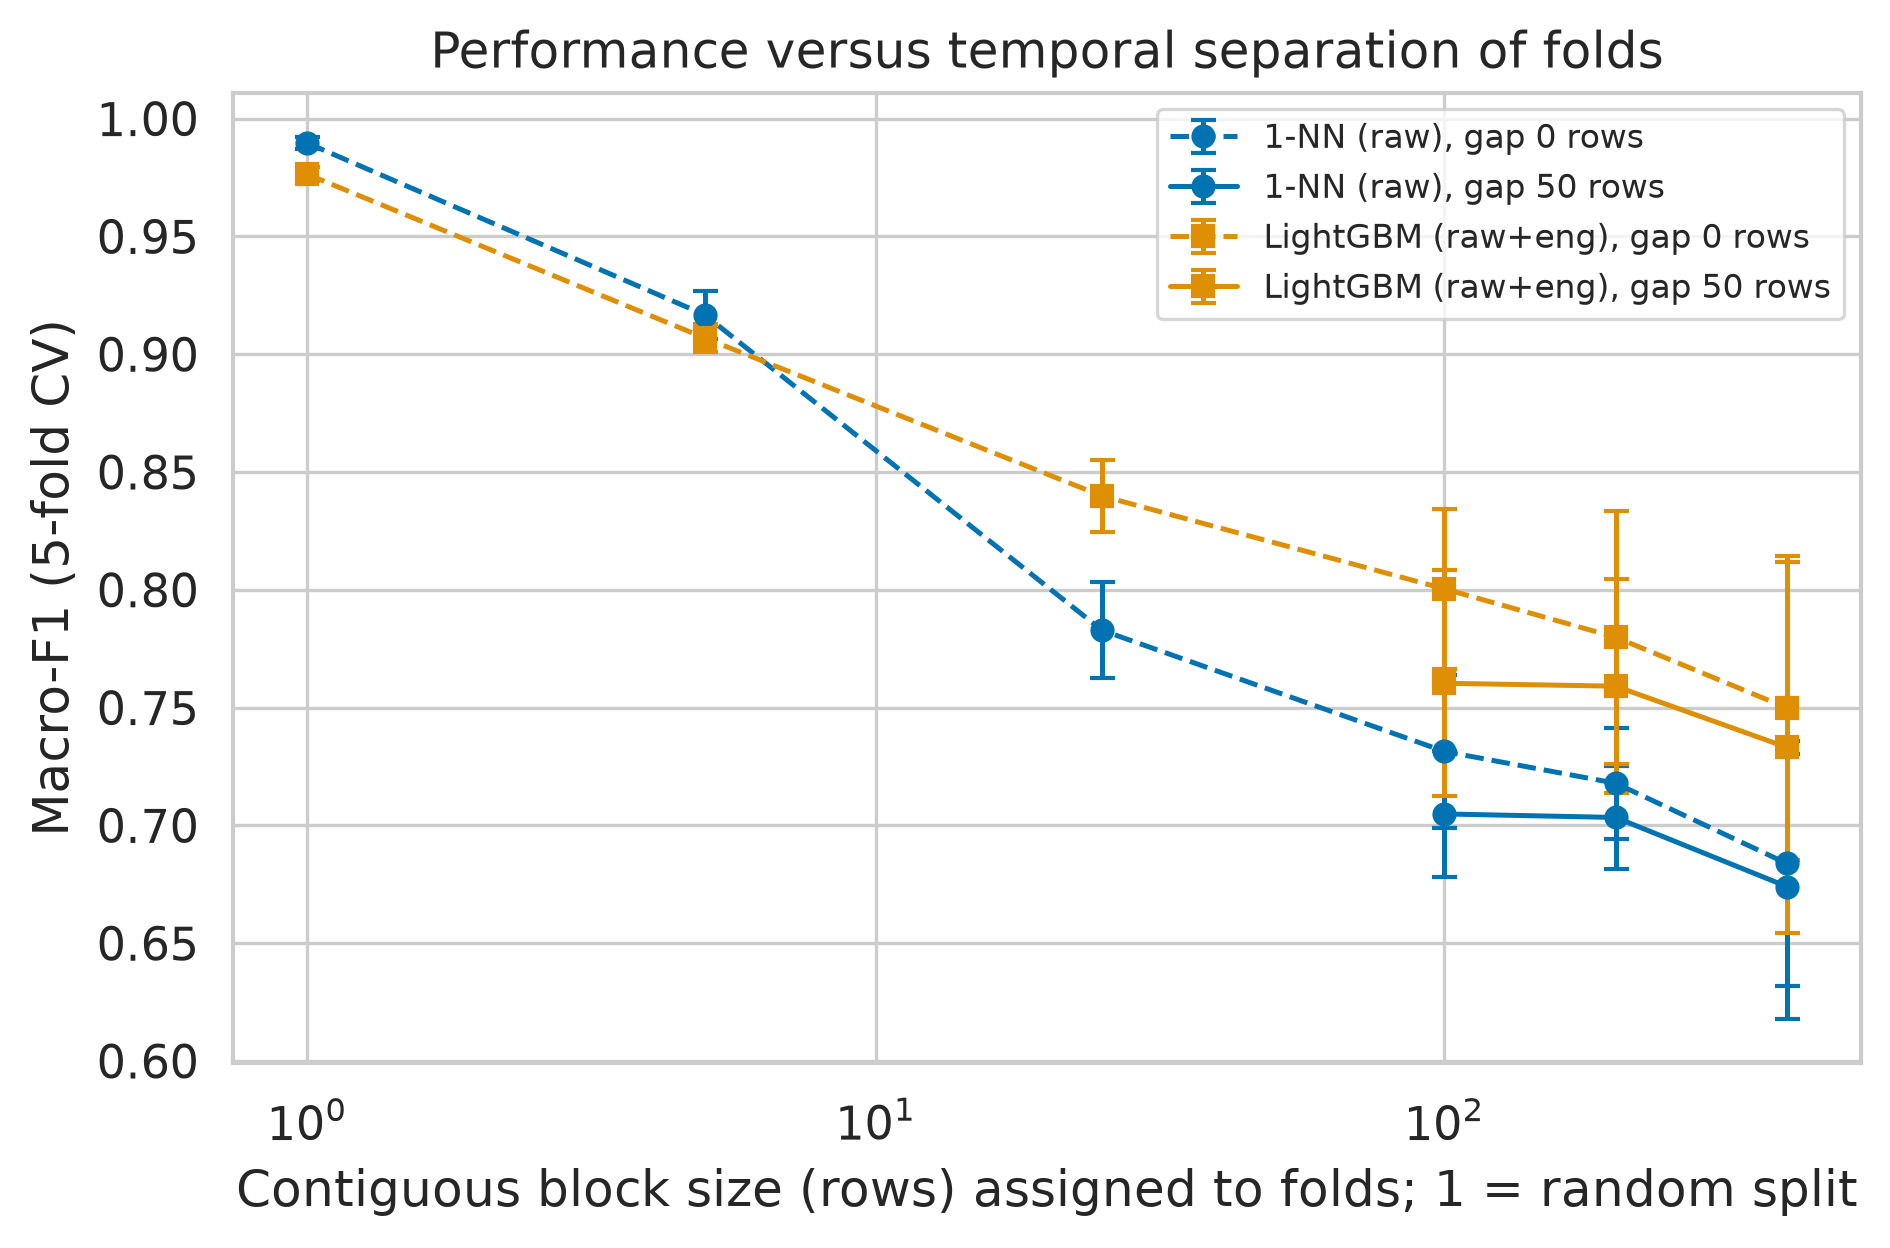

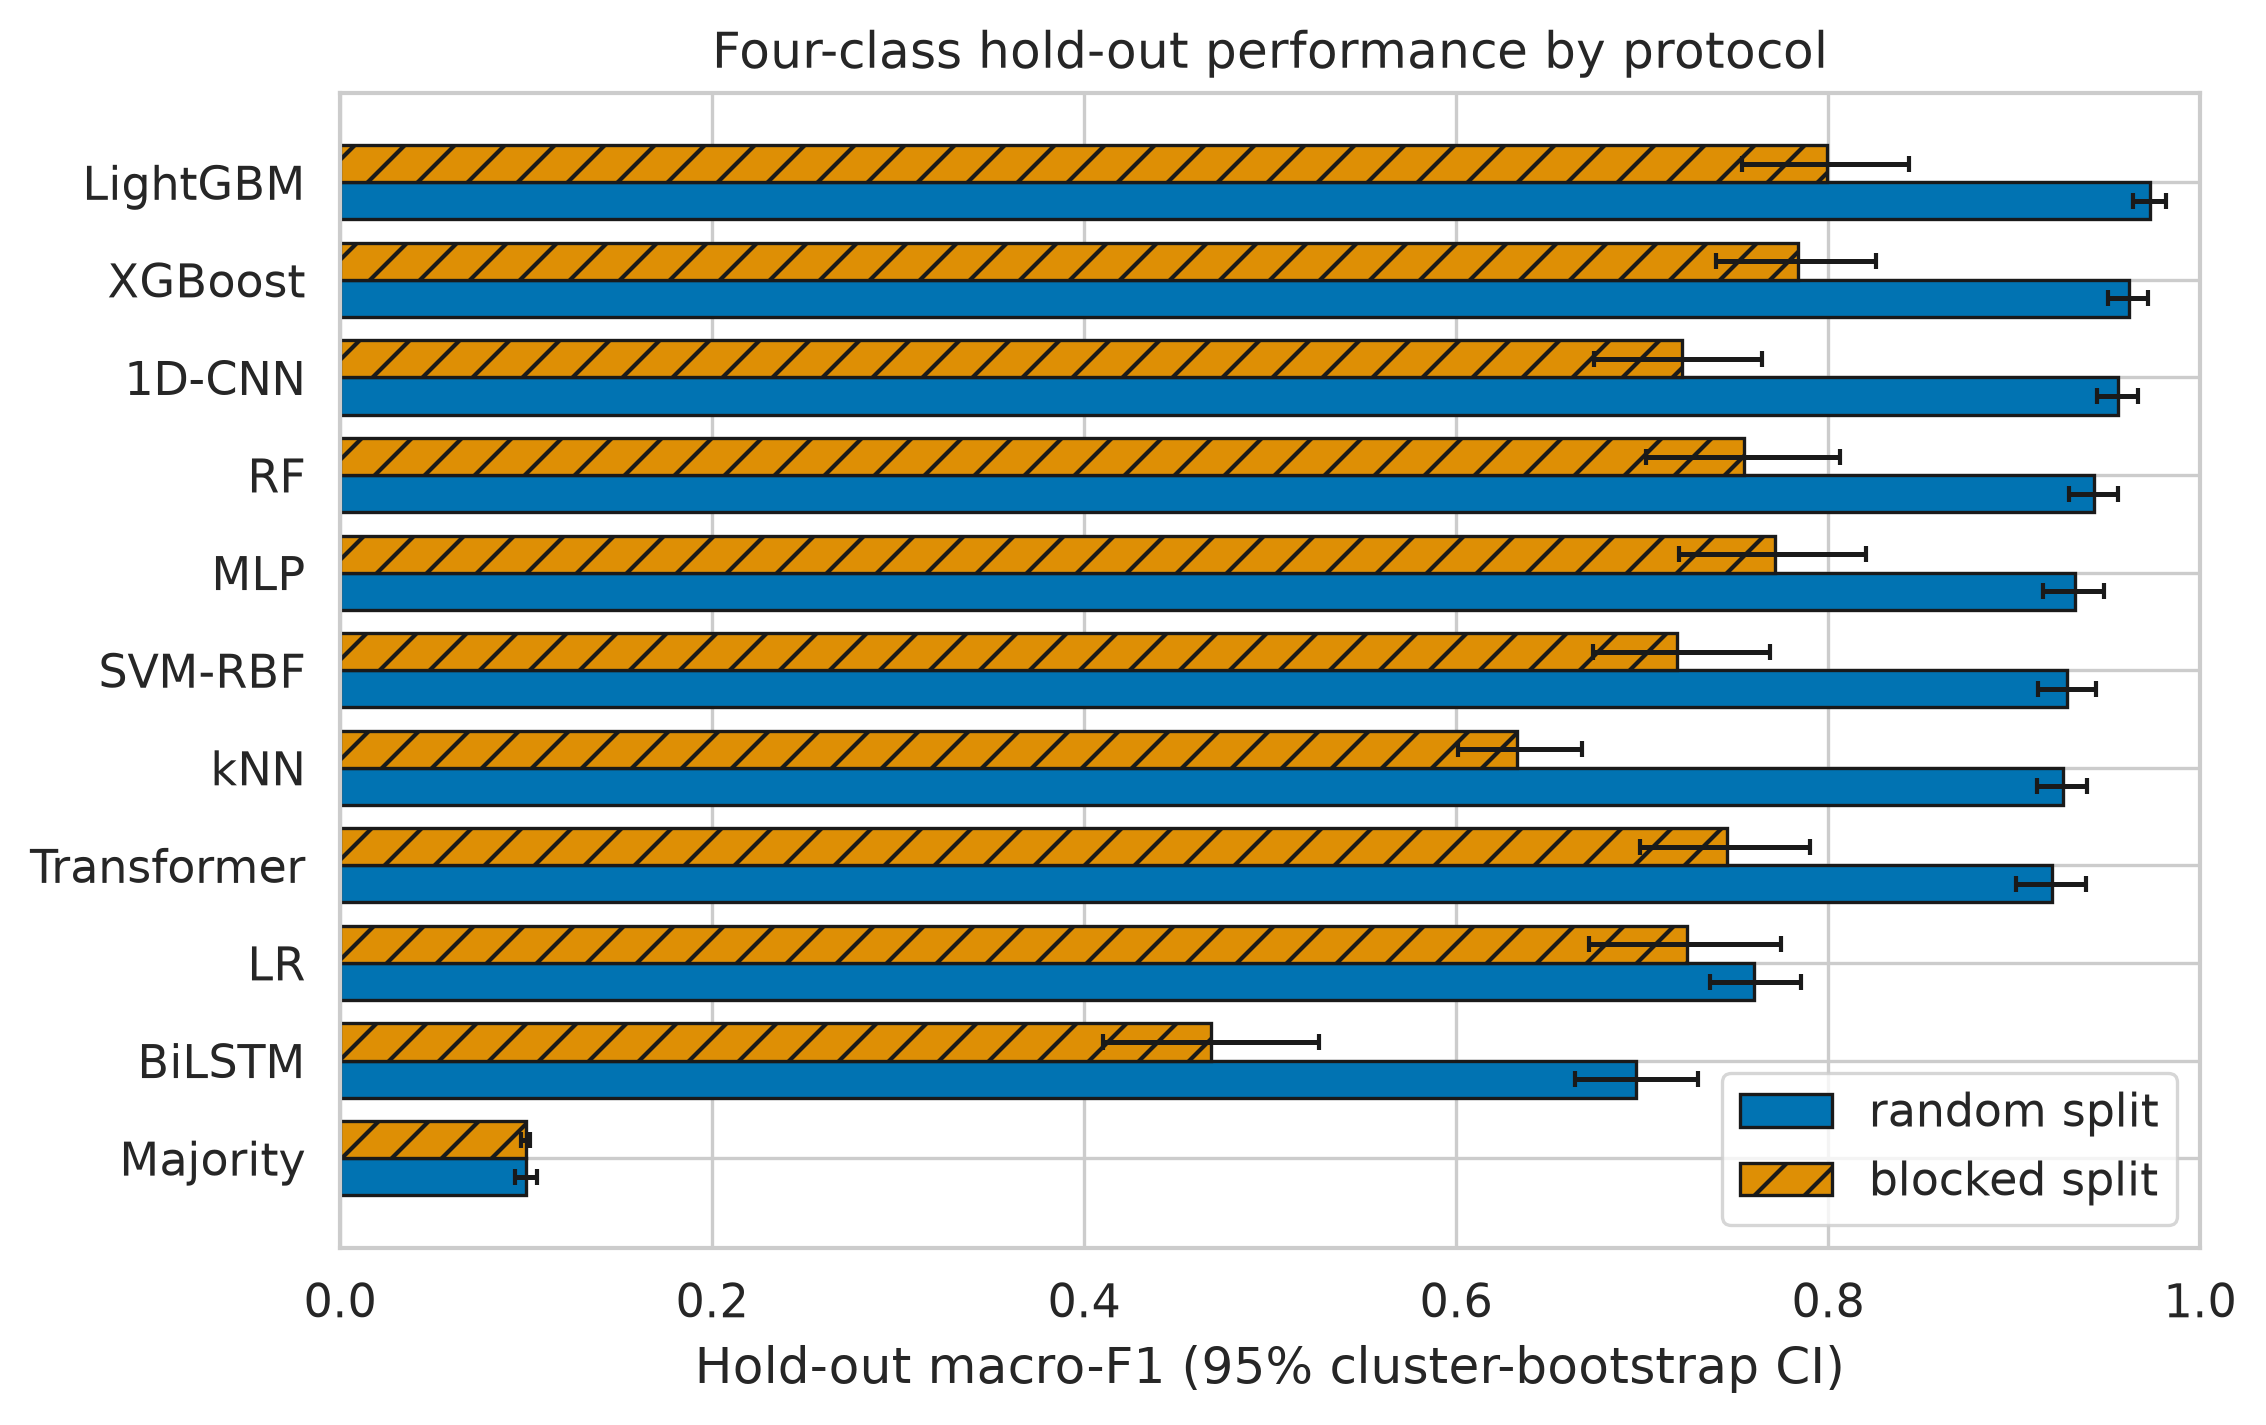

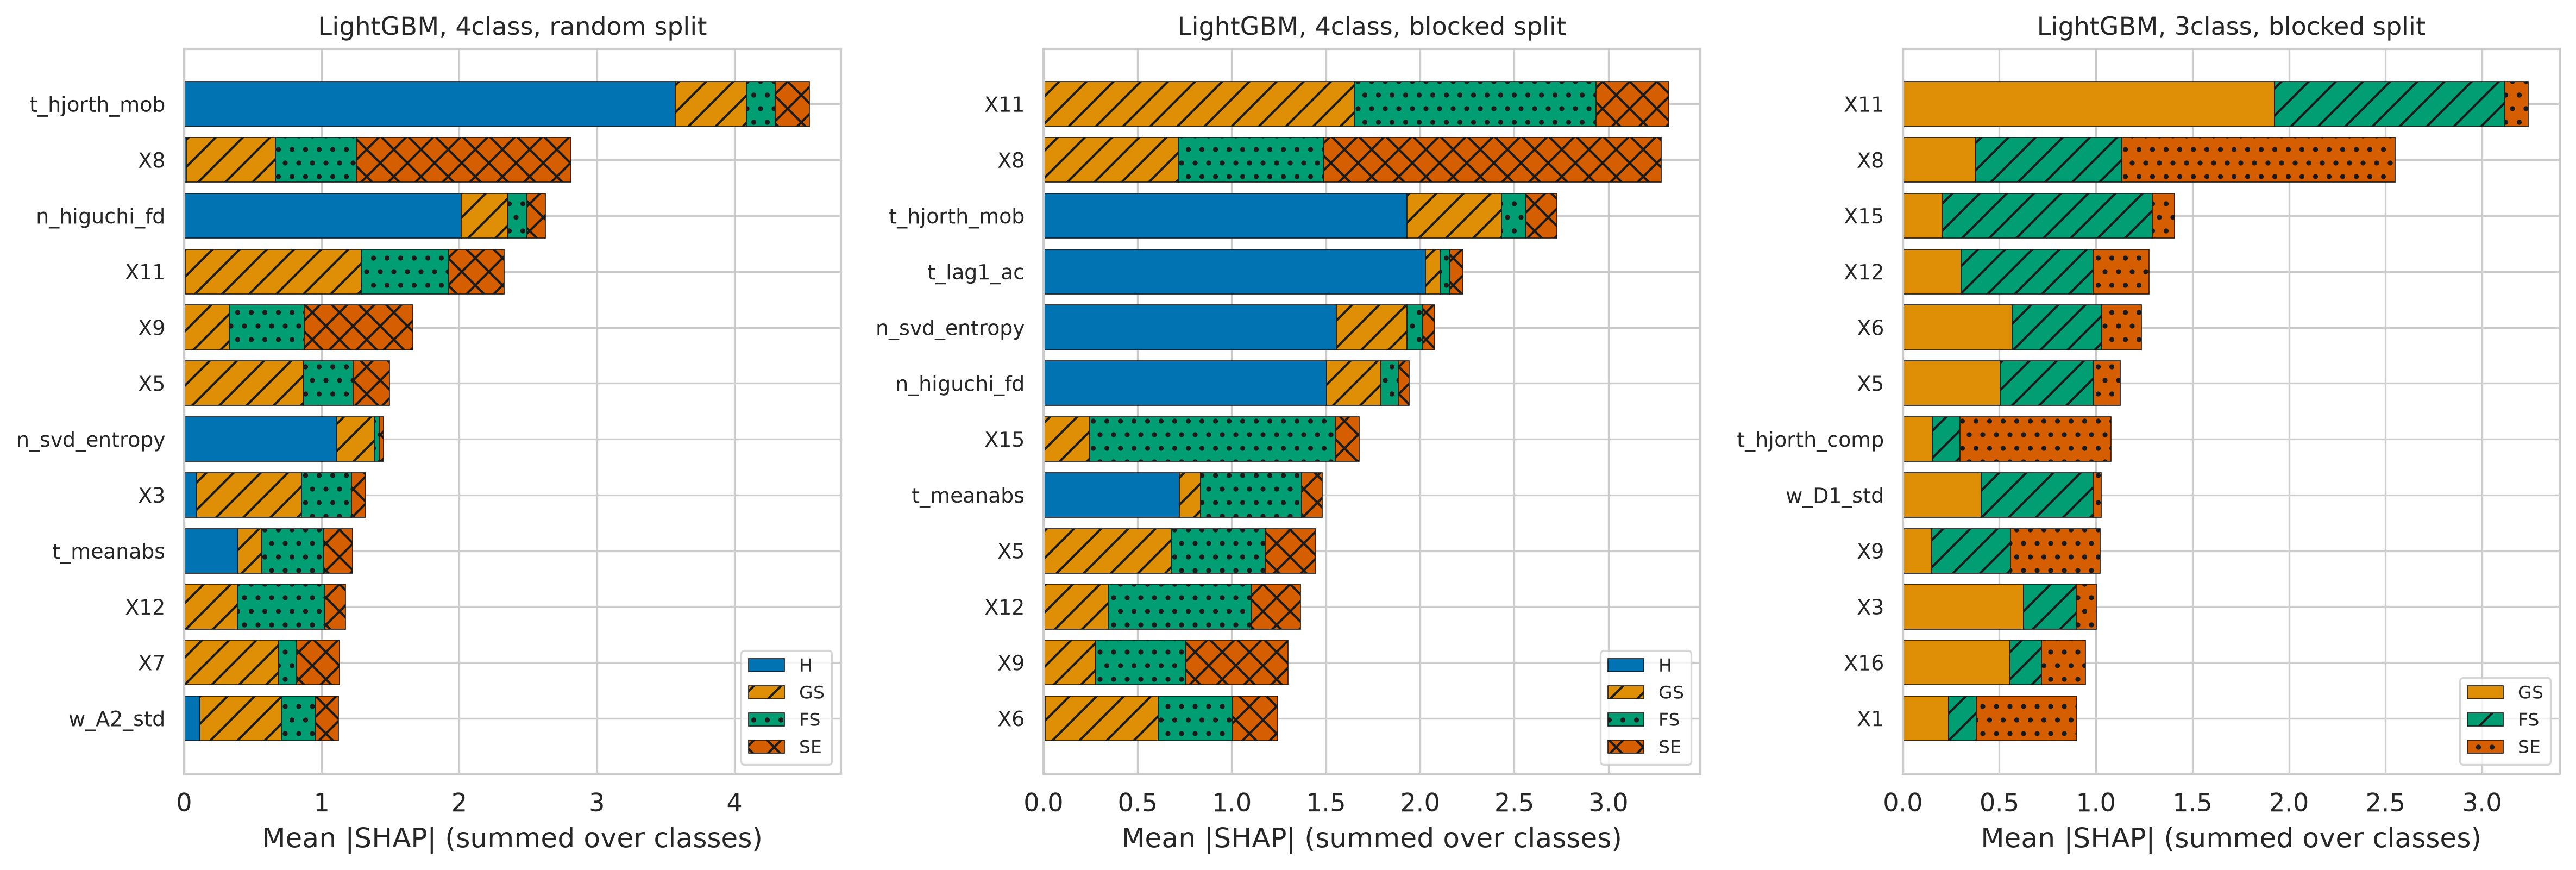

In [11]:
from IPython.display import Image, display
for f in ['fig_structure', 'fig_provenance', 'fig_block_curve', 'fig_holdout_bars', 'fig_shap']:
    display(Image(filename=f'figures/{f}.png', width=900))